# ANN Class Imbalance and Threshold Experiments

Compare a baseline ANN with SMOTE, random undersampling, and random oversampling for diabetes classification. All approaches share the same stratified data splits, preprocessing, ANN settings, and evaluation. Only training data is resampled.

## 1. Setup and data

### Imports

In [69]:
from pathlib import Path
import random
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

### Reproducibility settings

In [70]:
RANDOM_STATE = 42
BATCH_SIZE = 32
LEARNING_RATE = 0.001
EPOCHS = 100

### Dataset loading

In [71]:
def drive_to_direct_url(link):
    patterns = (r"/file/d/([a-zA-Z0-9_-]+)", r"id=([a-zA-Z0-9_-]+)", r"/open\?id=([a-zA-Z0-9_-]+)")
    for pattern in patterns:
        match = re.search(pattern, link)
        if match:
            return f"https://drive.google.com/uc?id={match.group(1)}"
    raise ValueError("Invalid Google Drive link")

In [72]:
local_dataset = Path("cleaned_diabetes.csv")
if not local_dataset.exists():
    local_dataset = Path("diadb-training/cleaned_diabetes.csv")

if local_dataset.exists():
    df = pd.read_csv(local_dataset)
else:
    drive_url = "https://drive.google.com/file/d/1AxchD_W4q0d9lXBOi2gyqunl_TmH3ktm/view?usp=sharing"
    df = pd.read_csv(drive_to_direct_url(drive_url))

print(f"Dataset shape: {df.shape}")
display(df.head())

Dataset shape: (5261, 13)


,age,gender,pulse_rate,systolic_bp,diastolic_bp,glucose,bmi,family_diabetes,hypertensive,family_hypertension,cardiovascular_disease,stroke,diabetic
0,42,Female,66,110,73,5.88,25.75,0,0,0,0,0,No
1,35,Female,60,125,68,5.71,19.58,0,0,0,0,0,No
2,62,Female,57,127,74,6.85,20.24,0,0,0,0,0,No
3,73,Male,55,193,112,6.28,21.72,0,0,0,0,0,No
4,68,Female,71,150,81,5.71,17.79,0,0,0,0,0,No


## 2. Data splitting

Use stratified 68% training, 12% validation, and 20% test splits. The label encoder is fitted on the target labels.

In [73]:
X = df.drop(columns="diabetic")
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df["diabetic"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.15, stratify=y_train, random_state=RANDOM_STATE
)

print(f"Training: {len(y_train):,}; validation: {len(y_val):,}; test: {len(y_test):,}")
print(f"Label mapping: {dict(enumerate(label_encoder.classes_))} (positive class = 1)")

Training: 3,576; validation: 632; test: 1,053
Label mapping: {0: 'No', 1: 'Yes'} (positive class = 1)


## 3. Class distributions

In [74]:
def class_counts(labels):
    counts = pd.Series(labels).value_counts().reindex([0, 1], fill_value=0)
    return {label_encoder.classes_[i]: int(counts[i]) for i in (0, 1)}

In [75]:
original_train_distribution = class_counts(y_train)
print("Training:", original_train_distribution)
print("Validation:", class_counts(y_val))
print("Test:", class_counts(y_test))

Training: {'No': 3343, 'Yes': 233}
Validation: {'No': 591, 'Yes': 41}
Test: {'No': 985, 'Yes': 68}


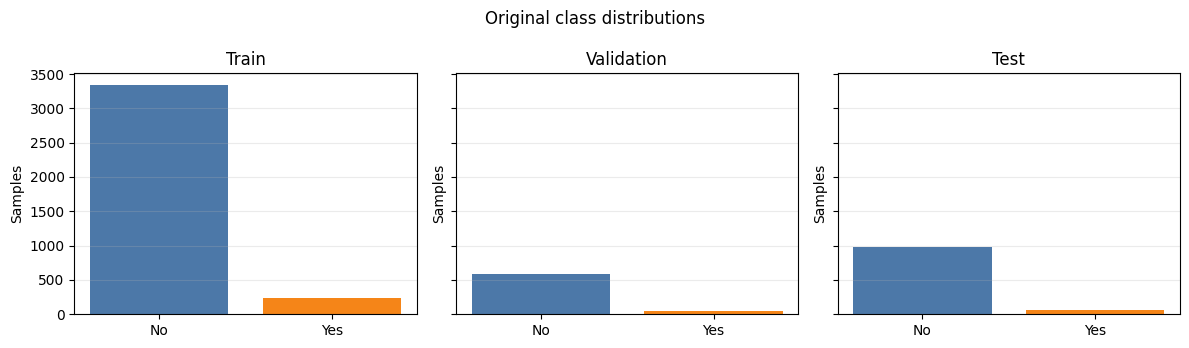

In [76]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, (name, labels) in zip(axes, [("Train", y_train), ("Validation", y_val), ("Test", y_test)]):
    counts = pd.Series(labels).value_counts().reindex([0, 1], fill_value=0)
    ax.bar(label_encoder.classes_, counts.values, color=["#4C78A8", "#F58518"])
    ax.set(title=name, ylabel="Samples")
    ax.grid(axis="y", alpha=0.25)
fig.suptitle("Original class distributions")
fig.tight_layout()
plt.show()

## 4. Shared model and evaluation procedure

Each strategy fits its own preprocessor and model. Validation and test rows are transformed without resampling.

In [77]:
torch.set_num_threads(1)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", device)

Training device: cpu


In [78]:
def build_preprocessor(features):
    numeric = features.select_dtypes(include="number").columns
    categorical = features.select_dtypes(exclude="number").columns
    return ColumnTransformer([
        ("num", StandardScaler(), numeric),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
    ])

In [79]:
def make_loader(features, labels, shuffle, generator=None):
    if hasattr(features, "toarray"):
        features = features.toarray()
    features = np.asarray(features, dtype=np.float32)
    labels = np.asarray(labels, dtype=np.float32).reshape(-1, 1)
    dataset = TensorDataset(torch.from_numpy(features), torch.from_numpy(labels))
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle, generator=generator)

In [80]:
def build_model(input_features):
    return nn.Sequential(
        nn.Linear(input_features, 64),
        nn.ReLU(),
        nn.Linear(64, 32),
        nn.ReLU(),
        nn.Linear(32, 1),
    ).to(device)

In [81]:
def predict(model, loader):
    model.eval()
    y_true, y_pred, y_prob = [], [], []
    with torch.no_grad():
        for features, labels in loader:
            probabilities = torch.sigmoid(model(features.to(device)).squeeze(1))
            predictions = (probabilities >= 0.5).int()
            y_true.extend(labels.numpy().ravel())
            y_pred.extend(predictions.cpu().numpy().ravel())
            y_prob.extend(probabilities.cpu().numpy().ravel())
    return np.asarray(y_true, dtype=int), np.asarray(y_pred, dtype=int), np.asarray(y_prob)

In [82]:
def calculate_metrics(y_true, y_pred, y_prob):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "PR-AUC": average_precision_score(y_true, y_prob),
    }

In [83]:
samplers = {
    "Baseline ANN": None,
    "SMOTE": SMOTE(random_state=RANDOM_STATE),
    "Random Undersampling": RandomUnderSampler(random_state=RANDOM_STATE),
    "Random Oversampling": RandomOverSampler(random_state=RANDOM_STATE),
}
results = {}
comparison_rows = []

In [84]:
def prepare_strategy_data(sampler):
    preprocessor = build_preprocessor(X_train)
    X_train_processed = preprocessor.fit_transform(X_train)
    X_val_processed = preprocessor.transform(X_val)
    X_test_processed = preprocessor.transform(X_test)
    if sampler is None:
        X_resampled, y_resampled = X_train_processed, y_train
    else:
        X_resampled, y_resampled = sampler.fit_resample(X_train_processed, y_train)
    return X_train_processed, X_val_processed, X_test_processed, X_resampled, y_resampled

In [85]:
def set_run_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    return torch.Generator().manual_seed(seed)

In [86]:
def train_model(X_resampled, y_resampled, input_features, seed):
    generator = set_run_seed(seed)
    train_loader = make_loader(X_resampled, y_resampled, shuffle=True, generator=generator)
    model = build_model(input_features)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    train_losses = []

    for epoch in range(EPOCHS):
        model.train()
        running_loss = 0.0
        for features, labels in train_loader:
            features, labels = features.to(device), labels.to(device)
            loss = criterion(model(features), labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * features.size(0)
        epoch_loss = running_loss / len(train_loader.dataset)
        train_losses.append(epoch_loss)
        if (epoch + 1) % 20 == 0 or epoch == 0:
            print(f"Epoch [{epoch + 1}/{EPOCHS}], Train Loss: {epoch_loss:.4f}")
    return model, train_losses

In [87]:
def run_strategy(strategy_name, sampler):
    print(f"\n### {strategy_name}")
    X_train_processed, X_val_processed, X_test_processed, X_resampled, y_resampled = prepare_strategy_data(sampler)
    resampled_distribution = class_counts(y_resampled)
    print("Original train distribution:", original_train_distribution)
    print("Resampled train distribution:", resampled_distribution)

    model, train_losses = train_model(
        X_resampled, y_resampled, X_train_processed.shape[1], RANDOM_STATE
    )
    val_loader = make_loader(X_val_processed, y_val, shuffle=False)
    test_loader = make_loader(X_test_processed, y_test, shuffle=False)
    val_true, val_pred, val_prob = predict(model, val_loader)
    test_true, test_pred, test_prob = predict(model, test_loader)
    validation_metrics = calculate_metrics(val_true, val_pred, val_prob)
    test_metrics = calculate_metrics(test_true, test_pred, test_prob)

    results[strategy_name] = {
        "model": model,
        "train_losses": train_losses,
        "y_val_true": val_true,
        "y_val_prob": val_prob,
        "y_true": test_true,
        "y_pred": test_pred,
        "y_prob": test_prob,
        "confusion_matrix": confusion_matrix(test_true, test_pred, labels=[0, 1]),
        "validation_metrics": validation_metrics,
        "test_metrics": test_metrics,
        "original_distribution": original_train_distribution,
        "resampled_distribution": resampled_distribution,
    }
    comparison_rows.append({
        "Strategy": strategy_name,
        "Original train distribution": original_train_distribution,
        "Resampled train distribution": resampled_distribution,
        **test_metrics,
    })
    print("Validation metrics:", {k: round(v, 4) for k, v in validation_metrics.items()})
    print("Test metrics:", {k: round(v, 4) for k, v in test_metrics.items()})

### 4.1 Baseline ANN

In [88]:
run_strategy("Baseline ANN", samplers["Baseline ANN"])


### Baseline ANN
Original train distribution: {'No': 3343, 'Yes': 233}
Resampled train distribution: {'No': 3343, 'Yes': 233}
Epoch [1/100], Train Loss: 0.3215
Epoch [20/100], Train Loss: 0.1507
Epoch [40/100], Train Loss: 0.1319
Epoch [60/100], Train Loss: 0.1156
Epoch [80/100], Train Loss: 0.0998
Epoch [100/100], Train Loss: 0.0855
Validation metrics: {'Accuracy': 0.9288, 'Precision': 0.4286, 'Recall': 0.2927, 'F1-score': 0.3478, 'ROC-AUC': np.float64(0.7642), 'PR-AUC': np.float64(0.2574)}
Test metrics: {'Accuracy': 0.9326, 'Precision': 0.4634, 'Recall': 0.2794, 'F1-score': 0.3486, 'ROC-AUC': np.float64(0.8072), 'PR-AUC': np.float64(0.3381)}


### 4.2 SMOTE

In [89]:
run_strategy("SMOTE", samplers["SMOTE"])


### SMOTE
Original train distribution: {'No': 3343, 'Yes': 233}
Resampled train distribution: {'No': 3343, 'Yes': 3343}
Epoch [1/100], Train Loss: 0.4655
Epoch [20/100], Train Loss: 0.2247
Epoch [40/100], Train Loss: 0.1457
Epoch [60/100], Train Loss: 0.1022
Epoch [80/100], Train Loss: 0.0802
Epoch [100/100], Train Loss: 0.0635
Validation metrics: {'Accuracy': 0.8718, 'Precision': 0.2143, 'Recall': 0.3659, 'F1-score': 0.2703, 'ROC-AUC': np.float64(0.7355), 'PR-AUC': np.float64(0.2513)}
Test metrics: {'Accuracy': 0.8813, 'Precision': 0.2336, 'Recall': 0.3676, 'F1-score': 0.2857, 'ROC-AUC': np.float64(0.7567), 'PR-AUC': np.float64(0.2463)}


### 4.3 Random undersampling

In [90]:
run_strategy("Random Undersampling", samplers["Random Undersampling"])


### Random Undersampling
Original train distribution: {'No': 3343, 'Yes': 233}
Resampled train distribution: {'No': 233, 'Yes': 233}
Epoch [1/100], Train Loss: 0.6776
Epoch [20/100], Train Loss: 0.4016
Epoch [40/100], Train Loss: 0.3600
Epoch [60/100], Train Loss: 0.3290
Epoch [80/100], Train Loss: 0.2897
Epoch [100/100], Train Loss: 0.2542
Validation metrics: {'Accuracy': 0.7706, 'Precision': 0.1905, 'Recall': 0.7805, 'F1-score': 0.3062, 'ROC-AUC': np.float64(0.8317), 'PR-AUC': np.float64(0.2582)}
Test metrics: {'Accuracy': 0.7863, 'Precision': 0.1822, 'Recall': 0.6618, 'F1-score': 0.2857, 'ROC-AUC': np.float64(0.8014), 'PR-AUC': np.float64(0.2346)}


### 4.4 Random oversampling

In [91]:
run_strategy("Random Oversampling", samplers["Random Oversampling"])


### Random Oversampling
Original train distribution: {'No': 3343, 'Yes': 233}
Resampled train distribution: {'No': 3343, 'Yes': 3343}
Epoch [1/100], Train Loss: 0.4799
Epoch [20/100], Train Loss: 0.2142
Epoch [40/100], Train Loss: 0.1132
Epoch [60/100], Train Loss: 0.0713
Epoch [80/100], Train Loss: 0.0466
Epoch [100/100], Train Loss: 0.0309
Validation metrics: {'Accuracy': 0.9003, 'Precision': 0.2963, 'Recall': 0.3902, 'F1-score': 0.3368, 'ROC-AUC': np.float64(0.7873), 'PR-AUC': np.float64(0.3033)}
Test metrics: {'Accuracy': 0.8955, 'Precision': 0.2941, 'Recall': 0.4412, 'F1-score': 0.3529, 'ROC-AUC': np.float64(0.7738), 'PR-AUC': np.float64(0.2999)}


## 5. Results

In [92]:
comparison = pd.DataFrame(comparison_rows).set_index("Strategy")
metric_names = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC"]
display(comparison.style.format({name: "{:.4f}" for name in metric_names}))

,Original train distribution,Resampled train distribution,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
Strategy,,,,,,,,
Baseline ANN,"{'No': 3343, 'Yes': 233}","{'No': 3343, 'Yes': 233}",0.9326,0.4634,0.2794,0.3486,0.8072,0.3381
SMOTE,"{'No': 3343, 'Yes': 233}","{'No': 3343, 'Yes': 3343}",0.8813,0.2336,0.3676,0.2857,0.7567,0.2463
Random Undersampling,"{'No': 3343, 'Yes': 233}","{'No': 233, 'Yes': 233}",0.7863,0.1822,0.6618,0.2857,0.8014,0.2346
Random Oversampling,"{'No': 3343, 'Yes': 233}","{'No': 3343, 'Yes': 3343}",0.8955,0.2941,0.4412,0.3529,0.7738,0.2999


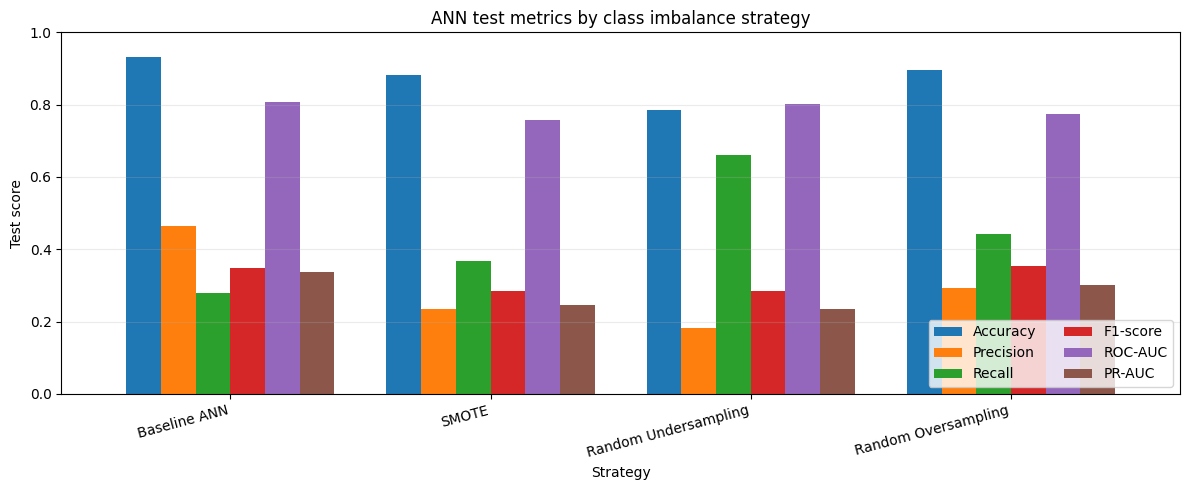

In [93]:
ax = comparison[metric_names].plot(kind="bar", figsize=(12, 5), ylim=(0, 1), width=0.8)
ax.set(ylabel="Test score", title="ANN test metrics by class imbalance strategy")
ax.set_xticklabels(ax.get_xticklabels(), rotation=15, ha="right")
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="lower right", ncol=2)
plt.tight_layout()
plt.show()

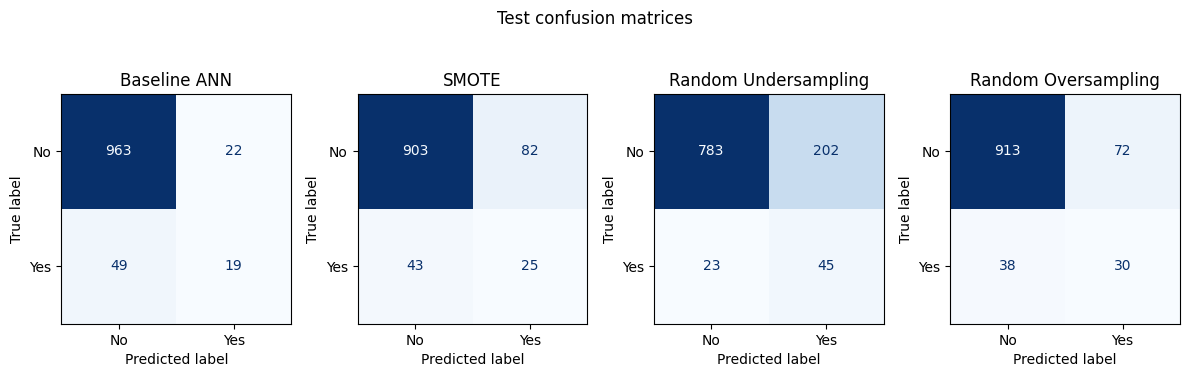

In [94]:
fig, axes = plt.subplots(1, len(results), figsize=(12, 3.8))
for ax, (name, result) in zip(axes, results.items()):
    ConfusionMatrixDisplay(
        confusion_matrix=result["confusion_matrix"],
        display_labels=label_encoder.classes_,
    ).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(name)
fig.suptitle("Test confusion matrices")
fig.tight_layout()
plt.show()

## 6. Interpretation of default-threshold results

Compare positive-class precision, recall, and F1 with ROC-AUC and PR-AUC. The preferred strategy depends on the observed tradeoff between missed cases and false alarms.

## 7. Validation threshold optimization

Select each approach's threshold using only its probabilities on the unchanged, unresampled validation set. The test set is not used in threshold selection.

In [95]:
THRESHOLDS = np.round(np.arange(0.10, 0.901, 0.01), 2)
threshold_curves = {}
validation_comparison_rows = []

for approach, result in results.items():
    y_true = result["y_val_true"]
    y_prob = result["y_val_prob"]
    curve_rows = []
    for threshold in THRESHOLDS:
        y_pred = (y_prob >= threshold).astype(int)
        curve_rows.append({"Threshold": threshold, **calculate_metrics(y_true, y_pred, y_prob)})

    curve = pd.DataFrame(curve_rows)
    best = curve.loc[curve["F1-score"].idxmax()]
    result["optimal_threshold"] = float(best["Threshold"])
    result["validation_optimized_metrics"] = best.to_dict()
    threshold_curves[approach] = curve
    validation_comparison_rows.append({
        "Approach": approach,
        "Optimal threshold": best["Threshold"],
        **{metric: best[metric] for metric in ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC"]},
    })

In [96]:
validation_comparison = pd.DataFrame(validation_comparison_rows)
validation_metric_names = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC"]
display(validation_comparison.style.format({
    "Optimal threshold": "{:.2f}",
    **{name: "{:.4f}" for name in validation_metric_names},
}))

,Approach,Optimal threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Baseline ANN,0.39,0.9288,0.4375,0.3415,0.3836,0.7642,0.2574
1,SMOTE,0.86,0.9051,0.2979,0.3415,0.3182,0.7355,0.2513
2,Random Undersampling,0.86,0.9003,0.3514,0.6341,0.4522,0.8317,0.2582
3,Random Oversampling,0.38,0.8987,0.3115,0.4634,0.3725,0.7873,0.3033


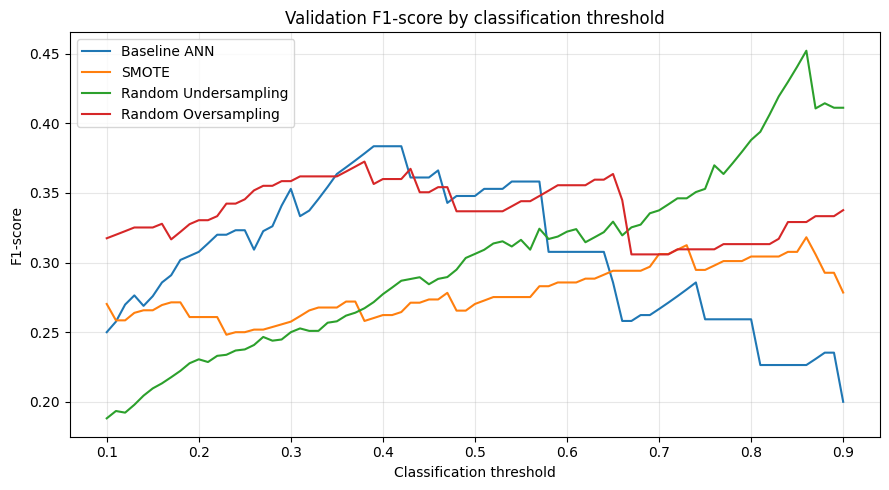

In [97]:
fig, ax = plt.subplots(figsize=(9, 5))
for approach, curve in threshold_curves.items():
    ax.plot(curve["Threshold"], curve["F1-score"], label=approach)
ax.set(title="Validation F1-score by classification threshold", xlabel="Classification threshold", ylabel="F1-score")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

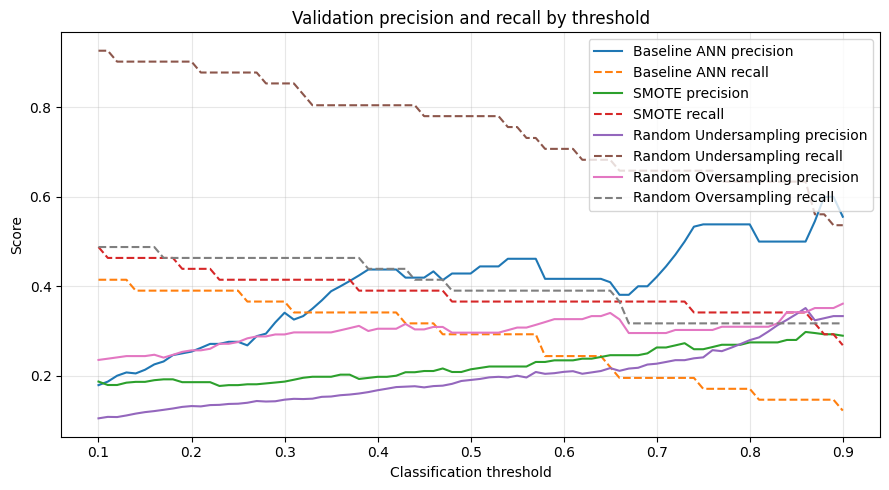

In [98]:
fig, ax = plt.subplots(figsize=(9, 5))
for approach, curve in threshold_curves.items():
    ax.plot(curve["Threshold"], curve["Precision"], label=f"{approach} precision")
    ax.plot(curve["Threshold"], curve["Recall"], linestyle="--", label=f"{approach} recall")
ax.set(title="Validation precision and recall by threshold", xlabel="Classification threshold", ylabel="Score")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

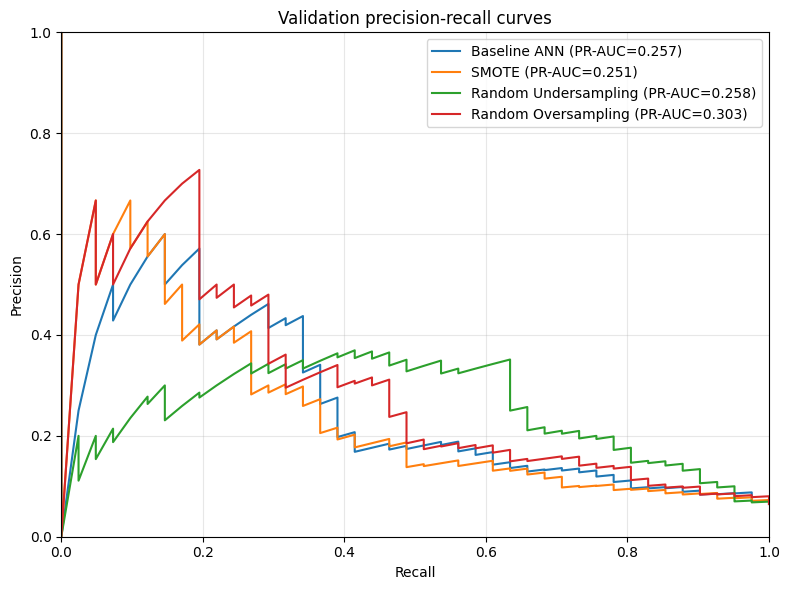

In [99]:
fig, ax = plt.subplots(figsize=(8, 6))
for approach, result in results.items():
    precision, recall, _ = precision_recall_curve(result["y_val_true"], result["y_val_prob"])
    ax.plot(recall, precision, label=f"{approach} (PR-AUC={result['validation_optimized_metrics']['PR-AUC']:.3f})")
ax.set(title="Validation precision-recall curves", xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1))
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

## 8. Final test evaluation

Evaluate the untouched test predictions at the default 0.50 threshold and each approach's validation-selected threshold. No threshold is selected or adjusted using test outcomes.

In [100]:
test_comparison_rows = []
for approach, result in results.items():
    y_true = result["y_true"]
    y_prob = result["y_prob"]
    result["test_metrics_default_threshold"] = calculate_metrics(y_true, (y_prob >= 0.50).astype(int), y_prob)
    result["test_metrics_optimized_threshold"] = calculate_metrics(
        y_true, (y_prob >= result["optimal_threshold"]).astype(int), y_prob
    )
    for threshold_name, threshold, metrics in [
        ("Default", 0.50, result["test_metrics_default_threshold"]),
        ("Validation optimized", result["optimal_threshold"], result["test_metrics_optimized_threshold"]),
    ]:
        test_comparison_rows.append({
            "Approach": approach,
            "Threshold selection": threshold_name,
            "Threshold": threshold,
            **metrics,
        })

test_comparison = pd.DataFrame(test_comparison_rows)
test_metric_names = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC"]
display(test_comparison.style.format({
    "Threshold": "{:.2f}",
    **{name: "{:.4f}" for name in test_metric_names},
}))

,Approach,Threshold selection,Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Baseline ANN,Default,0.50,0.9326,0.4634,0.2794,0.3486,0.8072,0.3381
1,Baseline ANN,Validation optimized,0.39,0.9231,0.3818,0.3088,0.3415,0.8072,0.3381
2,SMOTE,Default,0.50,0.8813,0.2336,0.3676,0.2857,0.7567,0.2463
3,SMOTE,Validation optimized,0.86,0.9069,0.3026,0.3382,0.3194,0.7567,0.2463
4,Random Undersampling,Default,0.50,0.7863,0.1822,0.6618,0.2857,0.8014,0.2346
5,Random Undersampling,Validation optimized,0.86,0.8851,0.2613,0.4265,0.3240,0.8014,0.2346
6,Random Oversampling,Default,0.50,0.8955,0.2941,0.4412,0.3529,0.7738,0.2999
7,Random Oversampling,Validation optimized,0.38,0.8917,0.2982,0.5000,0.3736,0.7738,0.2999


In [101]:
%pip install torchview

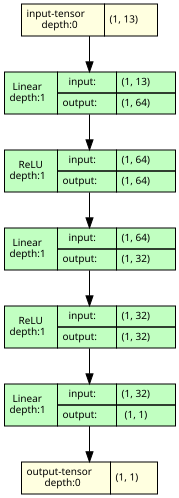

In [102]:
from torchview import draw_graph

model = results["Baseline ANN"]["model"]
graph = draw_graph(
    model,
    input_size=(1, model[0].in_features),
    expand_nested=True,
    graph_name="ANN",
    save_graph=True,
    filename="ann_architecture",
    directory=str(local_dataset.parent),
)
graph.visual_graph          # displays in a notebook